# 주간 변동성 예측 — S&P 500 · KOSPI · 금 ETF · 하이트진로

**AI 프로그래밍 및 실습 프로젝트**

주가가 오를지 내릴지(방향)는 맞히기 어렵지만, **얼마나 크게 움직일지(변동성)** 는
"클 때는 계속 크고 작을 때는 계속 작은" 성질(변동성 군집)이 있어 예측할 수 있다.
이 노트북은 이번 주까지의 일별 데이터로 **다음 주 변동성**을 예측한다.

| 단계 | 내용 | 강의 |
|---|---|---|
| 1 | 데이터 수집과 정제 | 2강 |
| 2 | 주간 변동성 계산, 계절성 탐색 | 2강 |
| 3 | 특성 공학, 시간 순서 분할, 표준화 | 2·3강 |
| 4 | 회귀: k-최근접 이웃, 선형·릿지·라쏘 | 3강 |
| 5 | 회귀: 결정 트리, 랜덤 포레스트, 그레이디언트 부스팅 | 5강 |
| 6 | 딥러닝: DNN, 1D CNN, LSTM | 7·8·9강 |
| 7 | 분류: 다음 주가 고변동 주간인가 (로지스틱 회귀 외) | 4강 |
| 8 | 특성 중요도, 계절성 특성의 효과 | 5강 |
| 9 | 웹 대시보드용 결과 내보내기 | — |

In [1]:
import json
import os
import warnings

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.ensemble import (
    HistGradientBoostingClassifier,
    HistGradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Lasso, LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. 데이터 수집

야후 파이낸스에서 일별 시세를 받는다. 받은 데이터는 `data/prices.csv`에 저장해 두고,
다운로드가 안 되는 환경에서는 저장된 파일을 읽는다.

- **S&P 500** (`^GSPC`), **KOSPI** (`^KS11`), **금 ETF** (`GLD`), **하이트진로** (`000080.KS`)
- 보조 지표: **VIX** (`^VIX`, 미국 변동성 지수), **원/달러 환율** (`KRW=X`)

In [2]:
ASSETS = {
    "SP500": {"ticker": "^GSPC", "name": "S&P 500"},
    "KOSPI": {"ticker": "^KS11", "name": "KOSPI"},
    "GOLD": {"ticker": "GLD", "name": "금 ETF (GLD)"},
    "HITE": {"ticker": "000080.KS", "name": "하이트진로"},
}
MACRO = {"VIX": "^VIX", "USDKRW": "KRW=X"}
START = "2005-01-01"
DATA_PATH = "data/prices.csv"
REFRESH = True  # False로 두면 저장된 파일만 사용


def download_prices():
    import yfinance as yf

    frames = []
    for key, ticker in {**{k: v["ticker"] for k, v in ASSETS.items()}, **MACRO}.items():
        df = yf.download(ticker, start=START, progress=False, auto_adjust=True)
        if df.empty:
            raise RuntimeError(f"{ticker} 다운로드 실패")
        df.columns = [c[0].lower() for c in df.columns]
        df = df.reset_index().rename(columns={"Date": "date"})
        df["asset"] = key
        frames.append(df[["date", "asset", "open", "high", "low", "close", "volume"]])
    return pd.concat(frames, ignore_index=True)


prices = None
if REFRESH:
    try:
        prices = download_prices()
        os.makedirs("data", exist_ok=True)
        prices.round(4).to_csv(DATA_PATH, index=False)
        print("야후 파이낸스에서 새로 받음")
    except Exception as e:  # 네트워크가 막힌 환경
        print("다운로드 실패, 저장된 파일 사용:", e)
if prices is None:
    prices = pd.read_csv(DATA_PATH, parse_dates=["date"])

prices["date"] = pd.to_datetime(prices["date"])
prices.groupby("asset")["date"].agg(["min", "max", "count"])

야후 파이낸스에서 새로 받음


,min,max,count
asset,,,
GOLD,2005-01-03,2026-11-24,5509
HITE,2005-01-03,2026-11-25,5418
KOSPI,2005-01-03,2026-11-25,5396
SP500,2005-01-03,2026-11-24,5509
USDKRW,2005-01-03,2026-11-25,5678
VIX,2005-01-03,2026-11-25,5512


### 데이터 정제

하이트진로(`000080.KS`)는 2009년 10월 재상장 이전 구간이 거래량 0, 가격 고정으로 채워져 있다.
거래가 없던 날(거래량 0이면서 고가 = 저가)은 변동성 0으로 잘못 계산되므로 제거한다.

In [3]:
prices = prices.dropna(subset=["close"]).sort_values(["asset", "date"])
is_asset = prices["asset"].isin(ASSETS)
dead = is_asset & (prices["volume"] == 0) & (prices["high"] == prices["low"])
print("제거한 무거래일:", dead.groupby(prices["asset"]).sum().loc[lambda s: s > 0].to_dict())
prices = prices[~dead].reset_index(drop=True)

# 일별 로그수익률과 고가-저가 범위
prices["r"] = prices.groupby("asset")["close"].transform(lambda s: np.log(s).diff())
prices["hl"] = np.log(prices["high"] / prices["low"])
prices = prices.dropna(subset=["r"]).reset_index(drop=True)
prices.groupby("asset")["date"].agg(["min", "max", "count"])

제거한 무거래일: {'HITE': 1228, 'KOSPI': 2}


,min,max,count
asset,,,
GOLD,2005-01-04,2026-11-24,5508
HITE,2009-10-20,2026-11-25,4189
KOSPI,2005-01-04,2026-11-25,5393
SP500,2005-01-04,2026-11-24,5508
USDKRW,2005-01-04,2026-11-25,5677
VIX,2005-01-04,2026-11-25,5511


## 2. 주간 변동성 계산

한 주(월~금)의 **실현 변동성**은 그 주 일별 로그수익률 제곱합의 제곱근이다.

$$RV_t = \sqrt{\sum_{d \in t} r_d^2}$$

거래일이 5일보다 적은 주는 5일 기준으로 환산하고, 3일 미만인 주는 버린다.
보기 쉽게 연율화한 값 $RV \times \sqrt{52} \times 100$ (%)도 함께 쓴다.

In [4]:
ANN = np.sqrt(52) * 100  # 주간 변동성 → 연율화 %


def to_weekly(daily):
    d = daily.copy()
    d["wk"] = d["date"].dt.to_period("W-FRI")
    d["r2"] = d["r"] ** 2
    d["hl2"] = d["hl"] ** 2
    w = (
        d.groupby(["asset", "wk"])
        .agg(n=("r", "size"), ss=("r2", "sum"), ret=("r", "sum"),
             hl2=("hl2", "sum"), volume=("volume", "mean"), last=("date", "max"))
        .reset_index()
    )
    # 아직 끝나지 않은 주 제외
    last_date = d.groupby("asset")["date"].max()
    week_end = w["wk"].dt.end_time.dt.normalize()
    w = w[week_end <= w["asset"].map(last_date)]
    w = w[w["n"] >= 3].copy()
    w["rv"] = np.sqrt(w["ss"] * 5 / w["n"]).clip(lower=1e-4)
    w["pk"] = np.sqrt(w["hl2"] * 5 / w["n"] / (4 * np.log(2))).clip(lower=1e-4)  # 파킨슨 변동성
    return w.reset_index(drop=True)


weekly_all = to_weekly(prices)
weekly = weekly_all[weekly_all["asset"].isin(ASSETS)].copy()
weekly["vol_ann"] = weekly["rv"] * ANN
weekly.groupby("asset")["vol_ann"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
asset,,,,,,,,
GOLD,1142.0,16.1,9.4,1.5,9.7,14.1,19.8,87.3
HITE,872.0,25.0,14.7,1.5,14.3,21.7,32.4,108.6
KOSPI,1120.0,18.1,14.4,2.0,10.3,14.2,20.8,151.9
SP500,1142.0,15.1,12.0,1.5,7.9,12.2,18.1,122.7


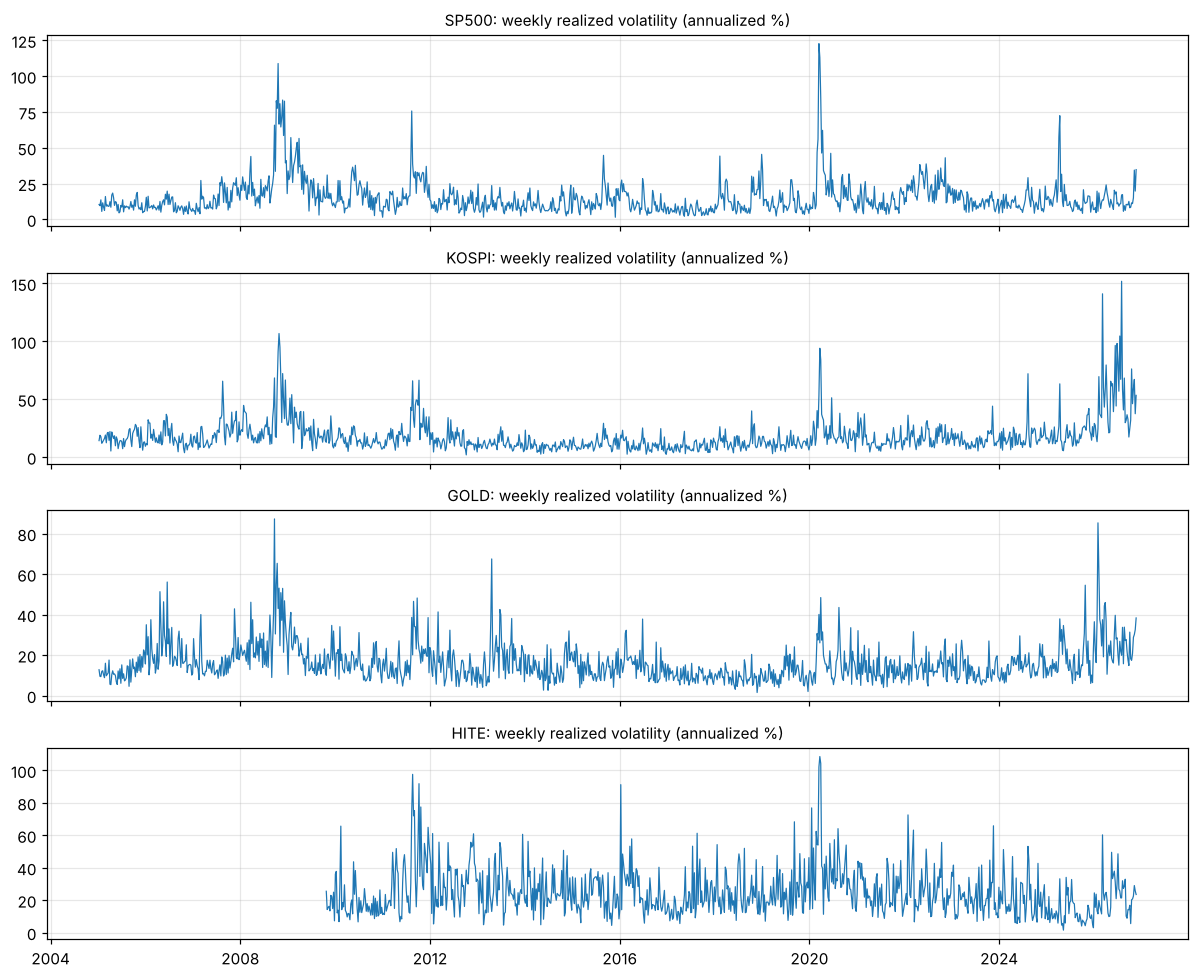

In [5]:
fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
for ax, key in zip(axes, ASSETS):
    w = weekly[weekly["asset"] == key]
    ax.plot(w["wk"].dt.end_time, w["vol_ann"], lw=0.8)
    ax.set_title(f"{key}: weekly realized volatility (annualized %)", fontsize=10)
plt.tight_layout()
plt.show()

변동성이 높은 구간이 뭉쳐서 나타난다(2008년 금융위기, 2020년 코로나 등).
이번 주 변동성과 다음 주 변동성의 상관을 확인한다.

In [6]:
ac = {}
for key in ASSETS:
    s = np.log(weekly.loc[weekly["asset"] == key, "rv"])
    ac[key] = {f"lag {k}주": round(s.autocorr(k), 3) for k in (1, 2, 4, 12)}
print("로그 변동성의 자기상관")
pd.DataFrame(ac).T

로그 변동성의 자기상관


,lag 1주,lag 2주,lag 4주,lag 12주
SP500,0.598,0.532,0.435,0.281
KOSPI,0.578,0.511,0.454,0.414
GOLD,0.442,0.431,0.400,0.274
HITE,0.360,0.296,0.149,0.137


수익률 자체의 자기상관은 0에 가깝지만 변동성의 자기상관은 높다.
이 차이가 "방향 대신 변동성을 예측한다"는 이 프로젝트의 근거다.

In [7]:
rc = {key: round(weekly.loc[weekly["asset"] == key, "ret"].autocorr(1), 3) for key in ASSETS}
print("주간 수익률의 1주 자기상관:", rc)

주간 수익률의 1주 자기상관: {'SP500': np.float64(-0.079), 'KOSPI': np.float64(-0.004), 'GOLD': np.float64(0.001), 'HITE': np.float64(-0.074)}


### 계절성 탐색

월별로 변동성이 달라지는지 본다. 해마다 변동성 수준이 다르므로,
각 주의 변동성을 **그 해 평균으로 나눈 비율**을 월별로 평균한다(1보다 크면 평소보다 변동성이 큰 달).
월 효과가 통계적으로 의미 있는지는 크러스컬-월리스 검정으로 확인한다.

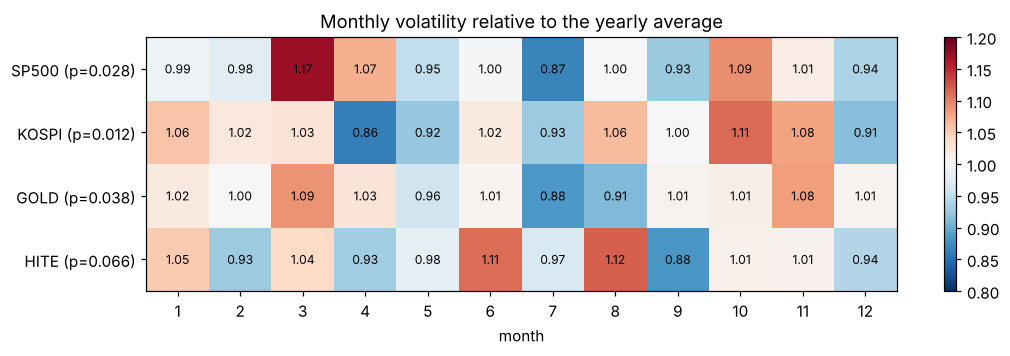

월 효과 검정 p값: {'SP500': 0.0284, 'KOSPI': 0.0118, 'GOLD': 0.0376, 'HITE': 0.0663}


월별 평균 수익률(%)


month,1,2,3,4,5,6,7,8,9,10,11,12
asset,,,,,,,,,,,,
SP500,0.10,-0.09,0.64,1.97,0.77,0.02,2.31,0.15,-0.55,0.61,1.73,0.50
KOSPI,0.71,1.15,0.21,3.52,1.39,-0.01,1.11,-1.23,0.86,-2.01,0.04,1.89
GOLD,3.56,1.21,-0.08,1.57,-0.54,-0.85,1.14,1.84,-0.29,0.30,0.50,0.89
HITE,-0.17,0.25,1.13,1.30,-2.18,-0.53,-0.69,-2.88,-0.08,2.75,-1.23,0.01


In [8]:
weekly["year"] = weekly["wk"].dt.end_time.dt.year
weekly["month"] = weekly["wk"].dt.end_time.dt.month
weekly["rel"] = weekly["vol_ann"] / weekly.groupby(["asset", "year"])["vol_ann"].transform("mean")

season = weekly.pivot_table(index="asset", columns="month", values="rel", aggfunc="mean").loc[list(ASSETS)]
season_p = {
    key: stats.kruskal(*[g["rel"].values for _, g in weekly[weekly["asset"] == key].groupby("month")]).pvalue
    for key in ASSETS
}

fig, ax = plt.subplots(figsize=(11, 3))
im = ax.imshow(season.values, cmap="RdBu_r", vmin=0.8, vmax=1.2, aspect="auto")
ax.set_xticks(range(12), [f"{m}" for m in range(1, 13)])
ax.set_yticks(range(4), [f"{k} (p={season_p[k]:.3f})" for k in season.index])
for i in range(4):
    for j in range(12):
        ax.text(j, i, f"{season.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_xlabel("month")
ax.set_title("Monthly volatility relative to the yearly average")
ax.grid(False)
plt.colorbar(im)
plt.show()
print("월 효과 검정 p값:", {k: round(float(v), 4) for k, v in season_p.items()})

# 월별 평균 수익률(%)도 함께 본다
prices["ym"] = prices["date"].dt.to_period("M")
monthly_ret = prices[prices["asset"].isin(ASSETS)].groupby(["asset", "ym"])["r"].sum().reset_index()
monthly_ret["month"] = monthly_ret["ym"].dt.month
season_ret = (monthly_ret.pivot_table(index="asset", columns="month", values="r", aggfunc="mean") * 100).loc[list(ASSETS)]
print("월별 평균 수익률(%)")
season_ret.round(2)

p값이 0.05보다 작으면 "월에 따라 변동성이 다르다"고 볼 수 있다.
위 결과를 그대로 읽고, 계절성 특성이 실제 예측에 도움이 되는지는 8절에서 따로 검증한다.

## 3. 특성 공학

이번 주(t)까지 알 수 있는 정보만으로 다음 주(t+1) 변동성을 예측한다.
타깃은 분포가 한쪽으로 치우친 변동성 대신 **로그 변동성**을 쓴다.

| 묶음 | 특성 | 의미 |
|---|---|---|
| 변동성 | `lrv`, `lrv_lag1~3` | 이번 주와 1~3주 전 로그 변동성 |
| | `lrv_m4`, `lrv_m12`, `lrv_m52` | 최근 4·12·52주 평균 (단기·중기·장기 수준) |
| | `lpk` | 고가-저가 범위로 구한 파킨슨 변동성 |
| 수익률 | `ret`, `absret`, `neg`, `ret_m4` | 주간 수익률, 절댓값, 하락분, 4주 누적 |
| 거래량 | `volr` | 최근 12주 평균 대비 거래량 |
| 거시 | `lvix`, `dvix`, `fx_lrv` | VIX 수준과 변화, 원/달러 환율 변동성 |
| 계절 | `sea_sin`, `sea_cos` | 예측 대상 주의 연중 위치 (1년 주기) |
| 자산 | `a_*` | 자산 구분 원-핫 |

In [9]:
macro_w = weekly_all[weekly_all["asset"] == "USDKRW"][["wk", "rv"]].rename(columns={"rv": "fx_rv"})
vix_w = (
    prices[prices["asset"] == "VIX"]
    .assign(wk=lambda d: d["date"].dt.to_period("W-FRI"))
    .groupby("wk")["close"].last().rename("vix").reset_index()
)


def make_features(w):
    w = w.sort_values("wk").copy()
    w["lrv"] = np.log(w["rv"])
    for k in (1, 2, 3):
        w[f"lrv_lag{k}"] = w["lrv"].shift(k)
    for k in (4, 12, 52):
        w[f"lrv_m{k}"] = w["lrv"].rolling(k).mean()
    w["lpk"] = np.log(w["pk"])
    w["absret"] = w["ret"].abs()
    w["neg"] = w["ret"].clip(upper=0)
    w["ret_m4"] = w["ret"].rolling(4).sum()
    w["volr"] = np.log((w["volume"] + 1) / (w["volume"].rolling(12).mean() + 1)).clip(-3, 3)
    w = w.merge(vix_w, on="wk", how="left").merge(macro_w, on="wk", how="left")
    w["vix"] = w["vix"].ffill()
    w["lvix"] = np.log(w["vix"])
    w["dvix"] = w["lvix"].diff()
    w["fx_lrv"] = np.log(w["fx_rv"]).ffill()
    # 예측 대상 주(다음 주)의 연중 위치
    target_mid = (w["wk"] + 1).dt.start_time + pd.Timedelta(days=2)
    angle = 2 * np.pi * target_mid.dt.dayofyear / 365.25
    w["sea_sin"], w["sea_cos"] = np.sin(angle), np.cos(angle)
    w["target_month"] = target_mid.dt.month
    # 타깃: 다음 주 로그 변동성
    w["y"] = w["lrv"].shift(-1)
    w["target_wk"] = w["wk"].shift(-1)
    return w


feat = pd.concat([make_features(g) for _, g in weekly.groupby("asset")], ignore_index=True)
for key in ASSETS:
    feat[f"a_{key}"] = (feat["asset"] == key).astype(float)

F_VOL = ["lrv", "lrv_lag1", "lrv_lag2", "lrv_lag3", "lrv_m4", "lrv_m12", "lrv_m52", "lpk"]
F_RET = ["ret", "absret", "neg", "ret_m4"]
F_ETC = ["volr", "lvix", "dvix", "fx_lrv"]
F_SEA = ["sea_sin", "sea_cos"]
F_ASSET = [f"a_{k}" for k in ASSETS]
FEATURES = F_VOL + F_RET + F_ETC + F_SEA + F_ASSET

feat = feat.dropna(subset=FEATURES).reset_index(drop=True)
latest = feat[feat["y"].isna()].groupby("asset").tail(1)  # 타깃이 아직 없는 마지막 주 → 실제 예측에 사용
data = feat.dropna(subset=["y"]).reset_index(drop=True)
print("학습 가능한 표본:", data.shape, "| 특성 수:", len(FEATURES))
data[["asset", "wk", "target_wk"] + F_VOL[:3] + ["y"]].tail(3)

학습 가능한 표본: (4068, 40) | 특성 수: 22


,asset,wk,target_wk,lrv,lrv_lag1,lrv_lag2,y
4065,SP500,2026-10-24/2026-10-30,2026-10-31/2026-11-06,-3.867805,-4.182732,-4.135466,-3.042066
4066,SP500,2026-10-31/2026-11-06,2026-11-07/2026-11-13,-3.042066,-3.867805,-4.182732,-3.597162
4067,SP500,2026-11-07/2026-11-13,2026-11-14/2026-11-20,-3.597162,-3.042066,-3.867805,-3.032395


### 시간 순서 분할

시계열을 무작위로 섞어 나누면 미래 정보가 훈련 세트에 섞여 성능이 부풀려진다.
그래서 **시간 순서대로** 나눈다. 표준화도 훈련 세트의 평균과 표준편차만 사용한다.

- 훈련: ~2017년 / 검증: 2018~2020년 (하이퍼파라미터 선택) / 테스트: 2021년~ (최종 평가)

In [10]:
TRAIN_END, VAL_END = "2017-12-31", "2020-12-31"
t_end = data["target_wk"].dt.end_time
m_tr = (t_end <= TRAIN_END).values
m_va = ((t_end > TRAIN_END) & (t_end <= VAL_END)).values
m_te = (t_end > VAL_END).values
m_trva = m_tr | m_va

X, y = data[FEATURES].values, data["y"].values
split_table = pd.DataFrame(
    {name: data[m].groupby("asset").size() for name, m in [("train", m_tr), ("val", m_va), ("test", m_te)]}
).loc[list(ASSETS)]
split_table.loc["합계"] = split_table.sum()
split_table

,train,val,test
asset,,,
SP500,626,156,308
KOSPI,613,153,302
GOLD,626,156,308
HITE,367,153,300
합계,2232,618,1218


## 4. 기준선

모델이 의미가 있으려면 단순한 규칙보다 나아야 한다.

- **Naive**: 다음 주 변동성 = 이번 주 변동성
- **4주 평균**: 다음 주 변동성 = 최근 4주 평균

평가지표
- **RMSE**: 로그 변동성 기준 오차 (작을수록 좋음)
- **MAE(%p)**: 연율화 변동성 기준 평균 절대 오차
- **R²**: 결정계수 (클수록 좋음)

In [11]:
results = {}     # 모델 이름 → 지표
test_pred = {}   # 모델 이름 → 테스트 예측(로그 변동성)
val_rmse = {}    # 모델 이름 → 검증 RMSE
fitted = {}      # 모델 이름 → 학습된 모델


def rmse(a, b):
    return float(np.sqrt(mean_squared_error(a, b)))


def evaluate(name, pred_te, group, pred_va=None, note=""):
    yt = y[m_te]
    row = {
        "group": group,
        "val_rmse": rmse(y[m_va], pred_va) if pred_va is not None else np.nan,
        "rmse": rmse(yt, pred_te),
        "mae_pp": float(mean_absolute_error(np.exp(yt) * ANN, np.exp(pred_te) * ANN)),
        "r2": float(r2_score(yt, pred_te)),
        "note": note,
    }
    for key in ASSETS:
        mk = (data.loc[m_te, "asset"] == key).values
        row[f"r2_{key}"] = float(r2_score(yt[mk], pred_te[mk]))
    results[name] = row
    test_pred[name] = pred_te
    val_rmse[name] = row["val_rmse"]
    print(f"{name:<22} test RMSE {row['rmse']:.4f} | MAE {row['mae_pp']:.2f}%p | R² {row['r2']:.3f} {note}")


evaluate("Naive (이번 주)", data.loc[m_te, "lrv"].values, "기준선", data.loc[m_va, "lrv"].values)
evaluate("4주 평균", data.loc[m_te, "lrv_m4"].values, "기준선", data.loc[m_va, "lrv_m4"].values)

Naive (이번 주)           test RMSE 0.5686 | MAE 8.15%p | R² 0.032 
4주 평균                  test RMSE 0.4997 | MAE 7.04%p | R² 0.252 


## 5. 회귀 모델 (3강)

훈련 세트로 학습하고 검증 세트로 하이퍼파라미터를 고른 뒤,
고른 설정으로 훈련+검증 세트에 다시 학습해 테스트 세트에서 평가한다.

In [12]:
def tune_and_test(name, group, make_model, grid, param_name):
    """검증 세트로 하이퍼파라미터를 고르고 테스트 세트에서 평가한다."""
    scores = {}
    for v in grid:
        model = make_model(v).fit(X[m_tr], y[m_tr])
        scores[v] = rmse(y[m_va], model.predict(X[m_va]))
    best = min(scores, key=scores.get)
    pred_va = make_model(best).fit(X[m_tr], y[m_tr]).predict(X[m_va])
    model = make_model(best).fit(X[m_trva], y[m_trva])
    evaluate(name, model.predict(X[m_te]), group, pred_va, note=f"({param_name}={best})")
    fitted[name] = model
    return scores


knn_scores = tune_and_test(
    "k-최근접 이웃", "3강 회귀",
    lambda k: make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k)),
    [5, 10, 20, 40, 80], "k")

_ = tune_and_test("선형 회귀", "3강 회귀",
              lambda _: make_pipeline(StandardScaler(), LinearRegression()), [None], "-")

ridge_scores = tune_and_test(
    "릿지 회귀", "3강 회귀",
    lambda a: make_pipeline(StandardScaler(), Ridge(alpha=a)),
    [0.01, 0.1, 1, 10, 100, 1000], "alpha")

lasso_scores = tune_and_test(
    "라쏘 회귀", "3강 회귀",
    lambda a: make_pipeline(StandardScaler(), Lasso(alpha=a, max_iter=10000)),
    [0.0001, 0.001, 0.003, 0.01, 0.03, 0.1], "alpha")

k-최근접 이웃               test RMSE 0.4831 | MAE 7.00%p | R² 0.301 (k=20)
선형 회귀                  test RMSE 0.4602 | MAE 6.56%p | R² 0.366 (-=None)
릿지 회귀                  test RMSE 0.4592 | MAE 6.56%p | R² 0.369 (alpha=100)


라쏘 회귀                  test RMSE 0.4557 | MAE 6.51%p | R² 0.378 (alpha=0.01)


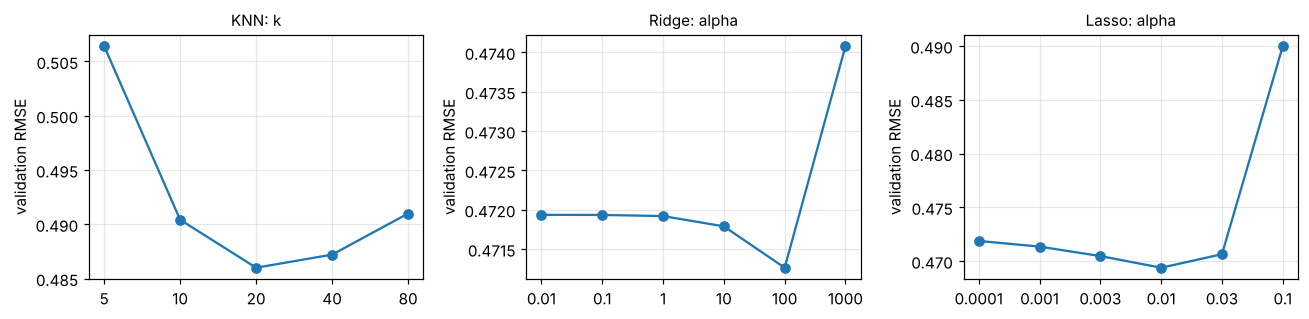

라쏘 계수가 0이 아닌 특성: 13 / 22


lpk         0.2082
lrv_m12     0.0977
lvix        0.0877
dvix        0.0549
lrv_m4      0.0431
lrv_lag1    0.0328
a_SP500    -0.0254
ret        -0.0234
ret_m4     -0.0175
a_HITE      0.0175
neg        -0.0160
a_GOLD      0.0092
lrv_lag2    0.0030
dtype: float64

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, (title, sc) in zip(axes, [("KNN: k", knn_scores), ("Ridge: alpha", ridge_scores), ("Lasso: alpha", lasso_scores)]):
    ax.plot([str(k) for k in sc], list(sc.values()), marker="o")
    ax.set_title(title, fontsize=10)
    ax.set_ylabel("validation RMSE")
plt.tight_layout()
plt.show()

# 라쏘가 남긴 특성
lasso = fitted["라쏘 회귀"][-1]
coef = pd.Series(lasso.coef_, index=FEATURES)
print("라쏘 계수가 0이 아닌 특성:", int((coef != 0).sum()), "/", len(FEATURES))
coef[coef != 0].sort_values(key=abs, ascending=False).round(4)

## 6. 트리 모델 (5강)

In [14]:
_ = tune_and_test(
    "결정 트리", "5강 트리",
    lambda d: DecisionTreeRegressor(max_depth=d, min_samples_leaf=20, random_state=SEED),
    [2, 3, 4, 5, 6, 8], "max_depth")

_ = tune_and_test(
    "랜덤 포레스트", "5강 트리",
    lambda leaf: RandomForestRegressor(n_estimators=300, min_samples_leaf=leaf, max_features=0.5,
                                       n_jobs=-1, random_state=SEED),
    [5, 10, 20, 40], "min_samples_leaf")

_ = tune_and_test(
    "그레이디언트 부스팅", "5강 트리",
    lambda lr: HistGradientBoostingRegressor(learning_rate=lr, max_iter=300, max_depth=3,
                                             l2_regularization=1.0, early_stopping=False, random_state=SEED),
    [0.01, 0.02, 0.05, 0.1], "learning_rate")

결정 트리                  test RMSE 0.4896 | MAE 7.09%p | R² 0.282 (max_depth=4)


랜덤 포레스트                test RMSE 0.4546 | MAE 6.57%p | R² 0.381 (min_samples_leaf=5)


그레이디언트 부스팅             test RMSE 0.4596 | MAE 6.63%p | R² 0.368 (learning_rate=0.02)


## 7. 딥러닝 모델 (7·8·9강)

- **DNN**: 위와 같은 표 형태 특성을 밀집층에 넣는다.
- **1D CNN**, **LSTM**: 특성 공학 없이 **최근 60거래일의 일별 시퀀스**
  (수익률, 절대 수익률, 고가-저가 범위)를 그대로 넣는다.

검증 세트로 조기 종료 시점(에포크 수)을 정한 뒤, 같은 에포크만큼 훈련+검증 세트로 다시 학습한다.

In [15]:
from tensorflow import keras  # 시세 다운로드 뒤에 불러온다 (먼저 불러오면 이 환경에서 yfinance 접속이 실패함)

import tensorflow as tf

keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()  # 실행할 때마다 같은 결과가 나오도록

SEQ_LEN = 60
seq_cols = ["r", "absr", "hl"]
prices["absr"] = prices["r"].abs()
daily_by_asset = {k: g.reset_index(drop=True) for k, g in prices[prices["asset"].isin(ASSETS)].groupby("asset")}


def build_sequences(rows):
    """각 (자산, 주)에 대해 그 주 마지막 거래일까지의 최근 60일 시퀀스를 만든다."""
    out = np.zeros((len(rows), SEQ_LEN, len(seq_cols)), dtype="float32")
    for i, (asset, last) in enumerate(zip(rows["asset"], rows["last"])):
        d = daily_by_asset[asset]
        end = d["date"].searchsorted(last, side="right")
        out[i] = d.loc[end - SEQ_LEN:end - 1, seq_cols].values * 100
    return out


S = build_sequences(data)
seq_mean, seq_std = S[m_tr].mean(axis=(0, 1)), S[m_tr].std(axis=(0, 1))
S = (S - seq_mean) / seq_std

scaler = StandardScaler().fit(X[m_tr])
Xs = scaler.transform(X).astype("float32")
y_mean, y_std = y[m_tr].mean(), y[m_tr].std()
ys = ((y - y_mean) / y_std).astype("float32")


def build_dnn():
    return keras.Sequential([
        keras.layers.Input(shape=(len(FEATURES),)),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(32, activation="relu"),
        keras.layers.Dense(1),
    ])


def build_cnn():
    return keras.Sequential([
        keras.layers.Input(shape=(SEQ_LEN, len(seq_cols))),
        keras.layers.Conv1D(32, 5, activation="relu", padding="same"),
        keras.layers.MaxPooling1D(2),
        keras.layers.Conv1D(32, 5, activation="relu", padding="same"),
        keras.layers.GlobalAveragePooling1D(),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(16, activation="relu"),
        keras.layers.Dense(1),
    ])


def build_lstm():
    return keras.Sequential([
        keras.layers.Input(shape=(SEQ_LEN, len(seq_cols))),
        keras.layers.LSTM(32),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(16, activation="relu"),
        keras.layers.Dense(1),
    ])


histories = {}


def fit_nn(name, build, inputs):
    keras.utils.set_random_seed(SEED)
    model = build()
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
    stop = keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)
    h = model.fit(inputs[m_tr], ys[m_tr], validation_data=(inputs[m_va], ys[m_va]),
                  epochs=200, batch_size=64, callbacks=[stop], verbose=0)
    histories[name] = h.history
    best_epoch = int(np.argmin(h.history["val_loss"])) + 1
    pred_va = model.predict(inputs[m_va], verbose=0).ravel() * y_std + y_mean

    keras.utils.set_random_seed(SEED)
    final = build()
    final.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
    final.fit(inputs[m_trva], ys[m_trva], epochs=best_epoch, batch_size=64, verbose=0)
    pred_te = final.predict(inputs[m_te], verbose=0).ravel() * y_std + y_mean
    evaluate(name, pred_te, "7~9강 딥러닝", pred_va, note=f"(epochs={best_epoch})")
    fitted[name] = final


fit_nn("DNN", build_dnn, Xs)
fit_nn("1D CNN (60일 시퀀스)", build_cnn, S)
fit_nn("LSTM (60일 시퀀스)", build_lstm, S)

DNN                    test RMSE 0.4586 | MAE 6.60%p | R² 0.370 (epochs=19)


1D CNN (60일 시퀀스)       test RMSE 0.4929 | MAE 7.16%p | R² 0.273 (epochs=1)


LSTM (60일 시퀀스)         test RMSE 0.4596 | MAE 6.52%p | R² 0.368 (epochs=7)


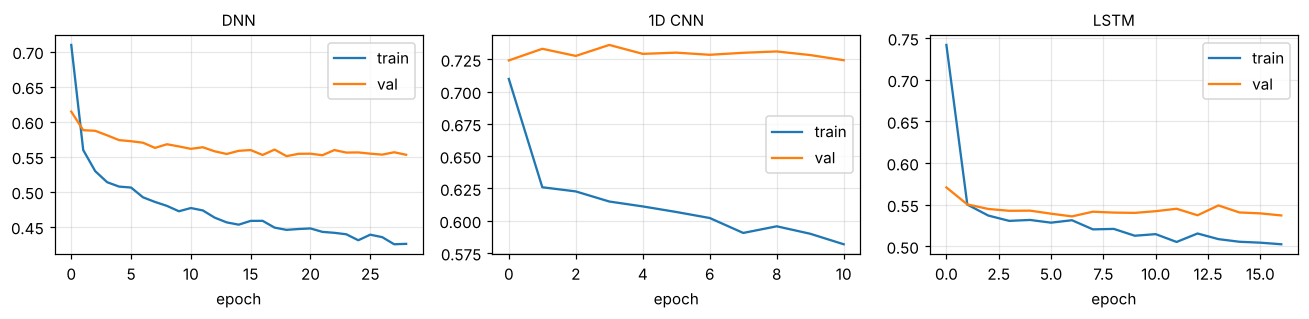

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, (name, h) in zip(axes, histories.items()):
    ax.plot(h["loss"], label="train")
    ax.plot(h["val_loss"], label="val")
    ax.set_title(name.split(" (")[0], fontsize=10)
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.show()

## 8. 회귀 결과 비교

In [17]:
res = pd.DataFrame(results).T
num_cols = [c for c in res.columns if c not in ("group", "note")]
res[num_cols] = res[num_cols].astype(float)
naive_rmse = res.loc["Naive (이번 주)", "rmse"]
res["vs_naive_%"] = (1 - res["rmse"] / naive_rmse) * 100
res_sorted = res.sort_values("rmse")
res_sorted[["group", "val_rmse", "rmse", "mae_pp", "r2", "vs_naive_%"] + [f"r2_{k}" for k in ASSETS]].round(3)

,group,val_rmse,rmse,mae_pp,r2,vs_naive_%,r2_SP500,r2_KOSPI,r2_GOLD,r2_HITE
랜덤 포레스트,5강 트리,0.476,0.455,6.574,0.381,20.045,0.394,0.467,0.276,0.192
라쏘 회귀,3강 회귀,0.469,0.456,6.514,0.378,19.847,0.407,0.473,0.213,0.211
DNN,7~9강 딥러닝,0.474,0.459,6.603,0.370,19.333,0.379,0.426,0.298,0.188
릿지 회귀,3강 회귀,0.471,0.459,6.556,0.369,19.228,0.409,0.456,0.213,0.190
LSTM (60일 시퀀스),7~9강 딥러닝,0.467,0.460,6.525,0.368,19.170,0.412,0.444,0.164,0.235
그레이디언트 부스팅,5강 트리,0.475,0.460,6.626,0.368,19.168,0.397,0.436,0.278,0.170
선형 회귀,3강 회귀,0.472,0.460,6.559,0.366,19.064,0.407,0.458,0.202,0.188
k-최근접 이웃,3강 회귀,0.486,0.483,6.999,0.301,15.032,0.315,0.315,0.257,0.122
결정 트리,5강 트리,0.494,0.490,7.093,0.282,13.887,0.266,0.344,0.184,0.109
1D CNN (60일 시퀀스),7~9강 딥러닝,0.543,0.493,7.161,0.273,13.318,0.185,0.364,0.182,0.115


검증 RMSE가 가장 낮은 모델: LSTM (60일 시퀀스)


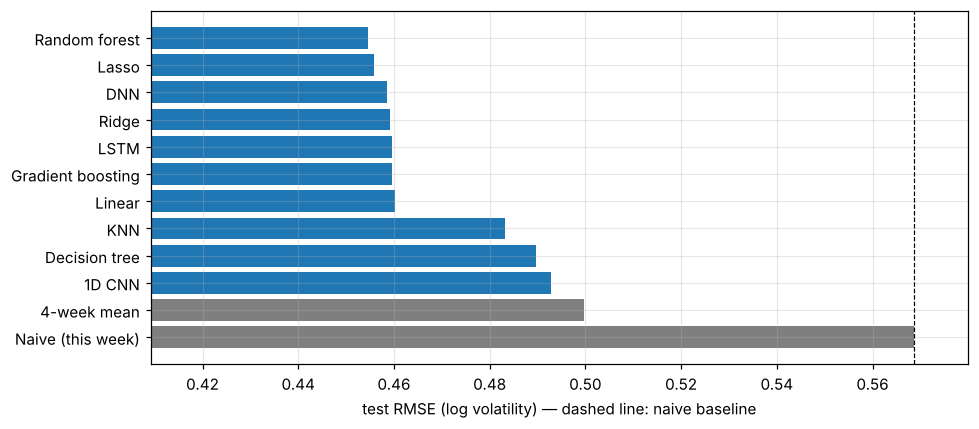

In [18]:
candidates = [n for n in results if results[n]["group"] != "기준선"]
BEST = min(candidates, key=lambda n: val_rmse[n])  # 테스트가 아니라 검증 성능으로 선택
print("검증 RMSE가 가장 낮은 모델:", BEST)

EN = {"Naive (이번 주)": "Naive (this week)", "4주 평균": "4-week mean", "k-최근접 이웃": "KNN",
      "선형 회귀": "Linear", "릿지 회귀": "Ridge", "라쏘 회귀": "Lasso", "결정 트리": "Decision tree",
      "랜덤 포레스트": "Random forest", "그레이디언트 부스팅": "Gradient boosting", "DNN": "DNN",
      "1D CNN (60일 시퀀스)": "1D CNN", "LSTM (60일 시퀀스)": "LSTM"}  # 그래프 글꼴 문제를 피하려고 영문 표기

fig, ax = plt.subplots(figsize=(9, 4))
order = res_sorted.index[::-1]
colors = ["tab:gray" if res.loc[n, "group"] == "기준선" else "tab:blue" for n in order]
ax.barh([EN[n] for n in order], res.loc[order, "rmse"], color=colors)
ax.axvline(naive_rmse, color="k", ls="--", lw=0.8)
ax.set_xlabel("test RMSE (log volatility) — dashed line: naive baseline")
ax.set_xlim(res["rmse"].min() * 0.9, res["rmse"].max() * 1.02)
plt.tight_layout()
plt.show()

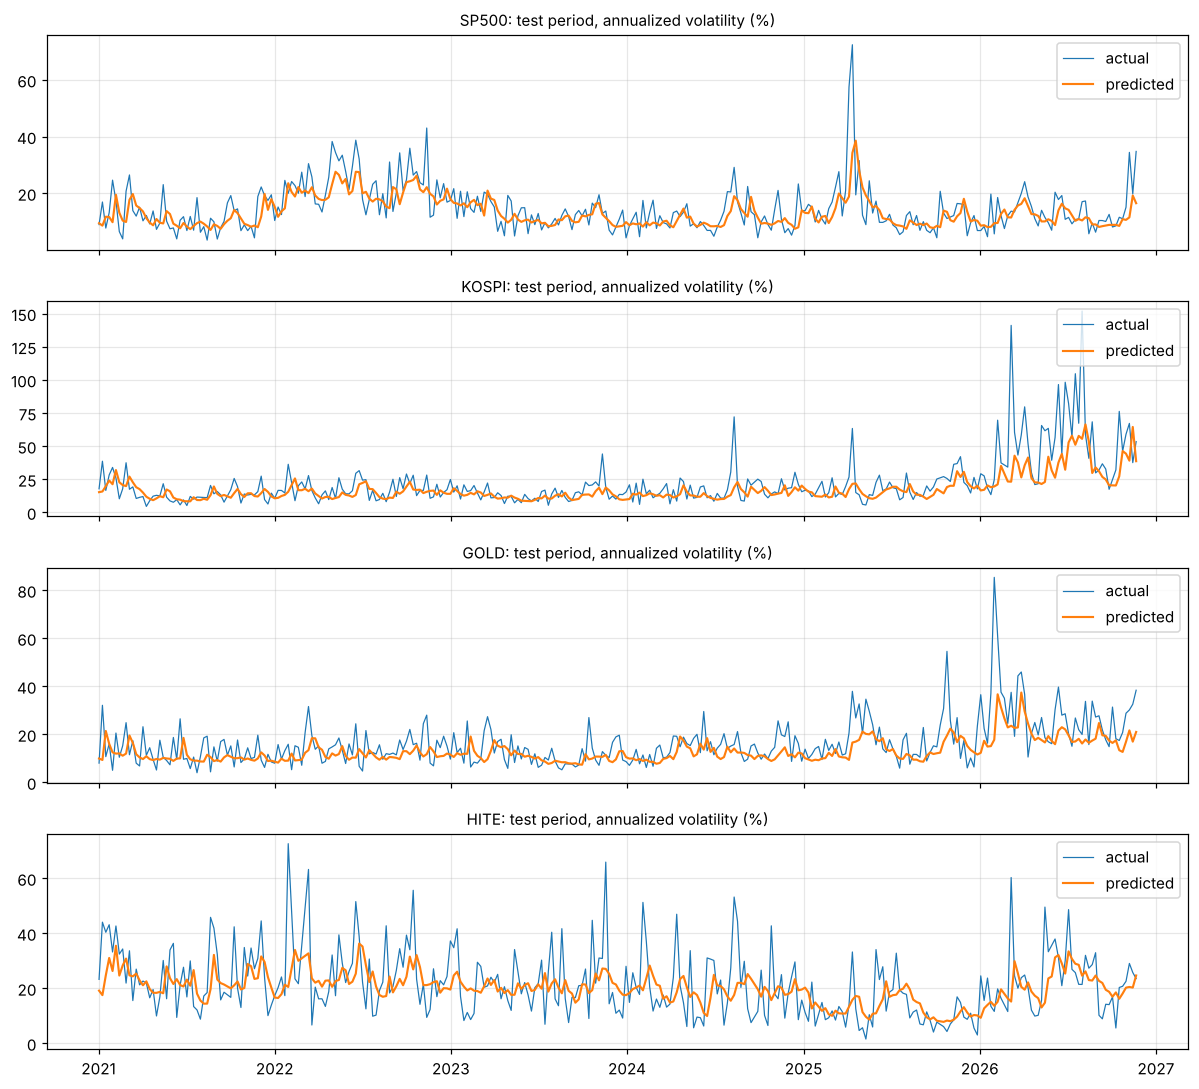

In [19]:
fig, axes = plt.subplots(4, 1, figsize=(11, 10), sharex=True)
te = data[m_te].assign(pred=np.exp(test_pred[BEST]) * ANN, actual=np.exp(y[m_te]) * ANN)
for ax, key in zip(axes, ASSETS):
    g = te[te["asset"] == key]
    ax.plot(g["target_wk"].dt.end_time, g["actual"], lw=0.8, label="actual")
    ax.plot(g["target_wk"].dt.end_time, g["pred"], lw=1.4, label="predicted")
    ax.set_title(f"{key}: test period, annualized volatility (%)", fontsize=10)
    ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

## 9. 분류: 다음 주는 고변동 주간인가 (4강)

자산마다 **훈련 기간 변동성의 상위 30% 경계**를 기준으로 잡고,
다음 주 변동성이 그 경계를 넘으면 1(고변동), 아니면 0으로 둔다.

기준선은 "이번 주가 고변동이면 다음 주도 고변동"이다.

In [20]:
thr = data[m_tr].groupby("asset")["y"].quantile(0.7)
y_cls = (data["y"] > data["asset"].map(thr)).astype(int).values
cur_hi = (data["lrv"] > data["asset"].map(thr)).astype(int).values
print("고변동 비율 — 훈련: %.2f, 검증: %.2f, 테스트: %.2f" % (y_cls[m_tr].mean(), y_cls[m_va].mean(), y_cls[m_te].mean()))

cls_results, cls_models, cls_proba = {}, {}, {}


def eval_cls(name, pred, proba=None):
    yt = y_cls[m_te]
    cls_results[name] = {
        "accuracy": accuracy_score(yt, pred),
        "precision": precision_score(yt, pred),
        "recall": recall_score(yt, pred),
        "f1": f1_score(yt, pred),
        "auc": roc_auc_score(yt, proba) if proba is not None else np.nan,
    }


eval_cls("기준선 (이번 주 상태 유지)", cur_hi[m_te])
for name, model in {
    "로지스틱 회귀": make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000)),
    "랜덤 포레스트": RandomForestClassifier(n_estimators=300, min_samples_leaf=10, n_jobs=-1, random_state=SEED),
    "그레이디언트 부스팅": HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200, max_depth=3, random_state=SEED),
}.items():
    model.fit(X[m_trva], y_cls[m_trva])
    proba = model.predict_proba(X[m_te])[:, 1]
    eval_cls(name, (proba >= 0.5).astype(int), proba)
    cls_models[name], cls_proba[name] = model, proba

cls_res = pd.DataFrame(cls_results).T
cls_res.round(3)

고변동 비율 — 훈련: 0.30, 검증: 0.24, 테스트: 0.29


,accuracy,precision,recall,f1,auc
기준선 (이번 주 상태 유지),0.749,0.564,0.561,0.563,NaN
로지스틱 회귀,0.787,0.753,0.390,0.514,0.793
랜덤 포레스트,0.762,0.685,0.322,0.438,0.761
그레이디언트 부스팅,0.767,0.691,0.345,0.460,0.759


정확도만 보면 안 된다. 고변동 주간은 전체의 30% 안팎이라 "항상 보통"이라고만 해도 정확도가 70%쯤 나온다.
그래서 정밀도, 재현율, F1, AUC를 함께 본다. 확률 0.5를 기준으로 자르면 모델은 확실할 때만 고변동이라고
답하므로 정밀도는 높고 재현율은 낮게 나오는 경향이 있다. 놓치는 쪽이 더 위험하다면 기준 확률을 낮추면 된다.

In [21]:
CLS_BEST = "로지스틱 회귀"
print(f"{CLS_BEST} 혼동 행렬 (행: 실제, 열: 예측)")
pd.DataFrame(confusion_matrix(y_cls[m_te], (cls_proba[CLS_BEST] >= 0.5).astype(int)),
             index=["실제 보통", "실제 고변동"], columns=["예측 보통", "예측 고변동"])

로지스틱 회귀 혼동 행렬 (행: 실제, 열: 예측)


,예측 보통,예측 고변동
실제 보통,822,45
실제 고변동,214,137


## 10. 무엇이 예측에 쓰였나

### 특성 중요도
테스트 세트에서 특성 하나를 섞었을 때 성능(R²)이 얼마나 떨어지는지로 중요도를 잰다(순열 중요도).

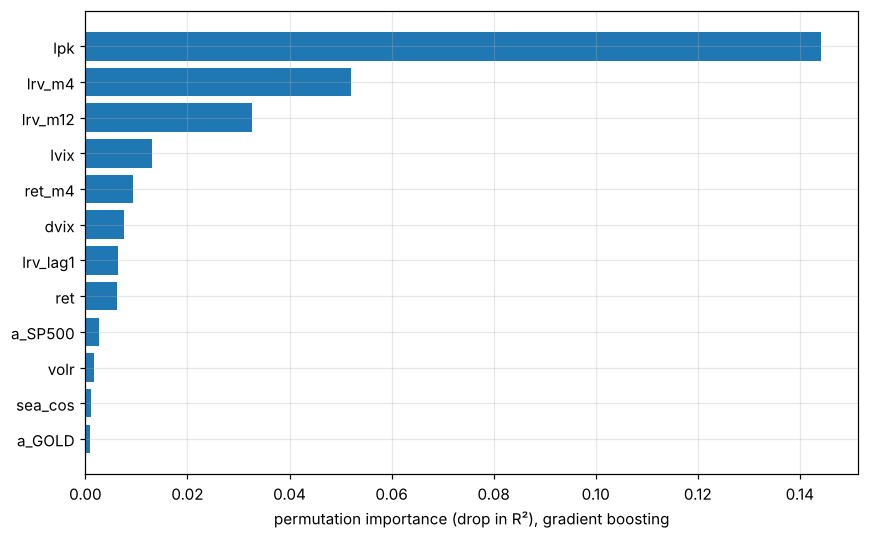

,그레이디언트 부스팅,릿지 회귀
lpk,0.1442,0.1484
lrv_m4,0.0521,0.0068
lrv_m12,0.0326,0.0414
lvix,0.0131,0.0136
ret_m4,0.0092,-0.0050
dvix,0.0076,0.0144
lrv_lag1,0.0063,0.0187
ret,0.0061,-0.0022
a_SP500,0.0027,0.0055
volr,0.0017,-0.0015


In [22]:
gb = fitted["그레이디언트 부스팅"]
imp_gb = permutation_importance(gb, X[m_te], y[m_te], n_repeats=10, random_state=SEED, scoring="r2")
imp_ridge = permutation_importance(fitted["릿지 회귀"], X[m_te], y[m_te], n_repeats=10, random_state=SEED, scoring="r2")
importance = pd.DataFrame({"그레이디언트 부스팅": imp_gb.importances_mean, "릿지 회귀": imp_ridge.importances_mean}, index=FEATURES)
importance = importance.sort_values("그레이디언트 부스팅", ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
top = importance.head(12)[::-1]
ax.barh(top.index, top["그레이디언트 부스팅"])
ax.set_xlabel("permutation importance (drop in R²), gradient boosting")
plt.tight_layout()
plt.show()
importance.head(12).round(4)

### 계절성 특성은 도움이 되는가

계절 특성(`sea_sin`, `sea_cos`)을 넣은 모델과 뺀 모델을 비교한다.
자산마다 계절 패턴이 다를 수 있으므로 **자산별로 따로 학습한 모델**로도 확인한다.

In [23]:
def r2_with_without(mask_fn, make_model):
    out = {}
    for label, cols in [("계절 특성 포함", FEATURES), ("계절 특성 제외", [f for f in FEATURES if f not in F_SEA])]:
        idx = [FEATURES.index(c) for c in cols]
        row = {}
        for key in ASSETS:
            tr, te_ = mask_fn(key, m_trva), mask_fn(key, m_te)
            model = make_model().fit(X[tr][:, idx], y[tr])
            mk = (data["asset"] == key).values & m_te
            row[key] = r2_score(y[mk], model.predict(X[mk][:, idx]))
        out[label] = row
    return pd.DataFrame(out).T


pooled = r2_with_without(lambda key, m: m,
                         lambda: HistGradientBoostingRegressor(learning_rate=0.05, max_iter=300, max_depth=3,
                                                               l2_regularization=1.0, random_state=SEED))
per_asset = r2_with_without(lambda key, m: m & (data["asset"] == key).values,
                            lambda: make_pipeline(StandardScaler(), Ridge(alpha=10)))
season_ablation = pd.concat({"통합 모델 (그레이디언트 부스팅)": pooled, "자산별 모델 (릿지)": per_asset})
print("테스트 R²")
season_ablation.round(4)

테스트 R²


SP500   KOSPI    GOLD    HITE
통합 모델 (그레이디언트 부스팅) 계절 특성 포함  0.3651  0.4311  0.2769  0.1402
                   계절 특성 제외  0.3680  0.4256  0.2652  0.1328
자산별 모델 (릿지)        계절 특성 포함  0.3969  0.4397  0.2958  0.1785
                   계절 특성 제외  0.3999  0.4414  0.2953  0.1839

## 11. 이번 주 예측과 웹 대시보드용 결과 내보내기

검증 성능이 가장 좋았던 모델로 **가장 최근에 끝난 주 다음 주**의 변동성을 예측하고,
웹 대시보드(`docs/index.html`)가 읽는 `docs/data.js`를 만든다.

예측 구간은 테스트 구간 잔차의 표준편차로 만든 80% 구간이다.

In [24]:
def predict_best(rows):
    Xn = rows[FEATURES].values
    model = fitted[BEST]
    if BEST == "DNN":
        return model.predict(scaler.transform(Xn).astype("float32"), verbose=0).ravel() * y_std + y_mean
    if "시퀀스" in BEST:
        Sn = (build_sequences(rows) - seq_mean) / seq_std
        return model.predict(Sn, verbose=0).ravel() * y_std + y_mean
    return model.predict(Xn)


resid_std = float(np.std(y[m_te] - test_pred[BEST]))
latest = latest.set_index("asset").loc[list(ASSETS)].reset_index()
latest_pred = predict_best(latest)
latest_phigh = cls_models[CLS_BEST].predict_proba(latest[FEATURES].values)[:, 1]

forecast_rows = []
for i, row in latest.iterrows():
    tw = row["wk"] + 1
    forecast_rows.append({
        "asset": row["asset"],
        "week": f"{tw.start_time + pd.Timedelta(days=2):%Y-%m-%d} ~ {tw.end_time:%Y-%m-%d}",  # 월~금
        "this_week_vol": float(row["rv"] * ANN),
        "forecast_vol": float(np.exp(latest_pred[i]) * ANN),
        "low80": float(np.exp(latest_pred[i] - 1.2816 * resid_std) * ANN),
        "high80": float(np.exp(latest_pred[i] + 1.2816 * resid_std) * ANN),
        "p_high": float(latest_phigh[i]),
        "threshold": float(np.exp(thr[row["asset"]]) * ANN),
    })
forecast = pd.DataFrame(forecast_rows)
print("예측 모델:", BEST)
forecast.round(2)

예측 모델: LSTM (60일 시퀀스)


,asset,week,this_week_vol,forecast_vol,low80,high80,p_high,threshold
0,SP500,2026-11-23 ~ 2026-11-27,34.76,31.20,17.42,55.88,0.94,16.64
1,KOSPI,2026-11-23 ~ 2026-11-27,53.35,42.74,23.86,76.55,0.98,18.25
2,GOLD,2026-11-23 ~ 2026-11-27,38.35,31.77,17.73,56.90,0.91,19.73
3,HITE,2026-11-23 ~ 2026-11-27,23.51,21.73,12.13,38.92,0.49,33.16


In [25]:
def r(v, n=4):
    return None if v is None or (isinstance(v, float) and np.isnan(v)) else round(float(v), n)


te = data[m_te].assign(
    pred=np.exp(test_pred[BEST]) * ANN,
    naive=np.exp(data.loc[m_te, "lrv"].values) * ANN,
    actual=np.exp(y[m_te]) * ANN,
    p_high=cls_proba[CLS_BEST],
)
export = {
    "generated": pd.Timestamp.now().strftime("%Y-%m-%d"),
    "last_date": prices["date"].max().strftime("%Y-%m-%d"),
    "best_model": BEST,
    "cls_model": CLS_BEST,
    "split": {"train_end": TRAIN_END, "val_end": VAL_END,
              "n_train": int(m_tr.sum()), "n_val": int(m_va.sum()), "n_test": int(m_te.sum())},
    "assets": [],
    "models": [
        {"name": n, "group": row["group"], "rmse": r(row["rmse"]), "mae_pp": r(row["mae_pp"], 2),
         "r2": r(row["r2"], 3), "vs_naive": r(row["vs_naive_%"], 1), "note": row["note"],
         "r2_by_asset": {k: r(row[f"r2_{k}"], 3) for k in ASSETS}}
        for n, row in res_sorted.iterrows()
    ],
    "classifiers": [{"name": n, **{k: r(v, 3) for k, v in row.items()}} for n, row in cls_res.iterrows()],
    "importance": [{"feature": f, "value": r(v)} for f, v in importance["그레이디언트 부스팅"].head(10).items()],
}
for i, key in enumerate(ASSETS):
    g = te[te["asset"] == key]
    export["assets"].append({
        "key": key,
        "name": ASSETS[key]["name"],
        "ticker": ASSETS[key]["ticker"],
        "forecast": {k: (v if isinstance(v, str) else r(v, 2)) for k, v in forecast_rows[i].items() if k != "asset"},
        "history": {
            "date": [d.strftime("%Y-%m-%d") for d in g["target_wk"].dt.end_time],
            "actual": [r(v, 2) for v in g["actual"]],
            "pred": [r(v, 2) for v in g["pred"]],
            "naive": [r(v, 2) for v in g["naive"]],
            "p_high": [r(v, 3) for v in g["p_high"]],
        },
        "season_vol": [r(v, 3) for v in season.loc[key]],
        "season_ret": [r(v, 2) for v in season_ret.loc[key]],
        "season_p": r(season_p[key]),
        "r2": r(results[BEST][f"r2_{key}"], 3),
        "r2_naive": r(results["Naive (이번 주)"][f"r2_{key}"], 3),
    })

os.makedirs("docs", exist_ok=True)
with open("docs/data.js", "w", encoding="utf-8") as f:
    f.write("window.VOL_DATA = " + json.dumps(export, ensure_ascii=False) + ";\n")
print("docs/data.js 저장:", os.path.getsize("docs/data.js") // 1024, "KB")

docs/data.js 저장: 54 KB


## 정리

- 주간 수익률의 자기상관은 0에 가깝지만 변동성의 자기상관은 높다. 그래서 방향보다 변동성이 예측하기 쉽다.
- 위 비교표에서 각 모델이 Naive 기준선을 얼마나 이기는지(`vs_naive_%`)가 이 프로젝트의 핵심 결과다.
- 시계열은 시간 순서로 나누고, 표준화는 훈련 세트 통계만 써야 미래 정보가 새지 않는다.
- 모델 선택은 검증 세트로 하고, 테스트 세트는 마지막에 한 번만 본다.

**한계**
- 예측하는 것은 변동의 크기이지 방향이 아니다. 이 결과만으로 수익을 낼 수 있다는 뜻이 아니다.
- 종목이 4개뿐이라 다른 자산에 그대로 통한다고 말하기는 어렵다.
- 테스트 기간이 한 구간(2021년~)이다. 구간을 옮겨 가며 반복 평가하면 더 믿을 만한 결론이 된다.